In [2]:
#a) 
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

In [3]:
data = pd.read_csv("creditcard.csv")
print(data.head())
print(data.shape)
print(data['Class'].value_counts)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
x = data.drop("Class", axis=1).values
y = data["Class"].values

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

Training data:  (227845, 30)
Testing data:  (56962, 30)


In [5]:
x_train = x_train[y_train==0]
print("Training data: ", x_train.shape)

Training data:  (227451, 30)


In [7]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)
print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

Training data:  (227451, 30)
Testing data:  (56962, 30)


In [8]:
#b) 
model = Sequential()

#Encoder
model.add(Dense(16, activation='relu', input_shape=(30,)))
model.add(Dense(8, activation='relu'))

#Decoder
model.add(Dense(16, activation='relu'))
model.add(Dense(30, activation='linear'))

model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = 'mse',
    metrics = ['mae']
)

model.summary()

C:\Users\ayush\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    x_train, x_train, 
    epochs=10,
    batch_size = 256,
    validation_split=0.2
)

Epoch 1/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.8339 - mae: 0.6166 - val_loss: 0.6862 - val_mae: 0.5695
Epoch 2/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.6361 - mae: 0.5439 - val_loss: 0.5721 - val_mae: 0.5190
Epoch 3/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5609 - mae: 0.5095 - val_loss: 0.5286 - val_mae: 0.4992
Epoch 4/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.5293 - mae: 0.4954 - val_loss: 0.5095 - val_mae: 0.4900
Epoch 5/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.5119 - mae: 0.4874 - val_loss: 0.4970 - val_mae: 0.4832
Epoch 6/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4991 - mae: 0.4815 - val_loss: 0.4847 - val_mae: 0.4772
Epoch 7/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4868 - mae: 0.4729 - val_loss: 0.4719 - val_mae: 0.4668
Epoch 8/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.4760 - mae: 0.4653 - val_loss: 0.4621 - val_mae: 0.4601
Epoch 9/10
711/711 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - lo

In [11]:
#c)
#train
train_predictions = model.predict(x_train)
train_errors = np.mean(np.square(x_train - train_predictions), axis=1)

threshold = np.mean(train_errors) + 3*np.std(train_errors)
print("Threshold: ", threshold)

#test
test_predictions = model.predict(x_test)
errors = np.mean(np.square(x_test - test_predictions), axis=1)

y_pred = (errors > threshold).astype(int)
print("Predicted Transactions:")
print(y_pred[:20])

print("Fraud detected: ", np.sum(y_pred))

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step
Threshold:  5.356647916332615
1781/1781 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
Predicted Transactions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Fraud detected:  227


In [14]:
print("Confusion matrix: ", confusion_matrix(y_test, y_pred))
print("Classification report: ")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion matrix:  [[56700   164]
 [   35    63]]
Classification report: 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.28      0.64      0.39        98

    accuracy                           1.00     56962
   macro avg       0.64      0.82      0.69     56962
weighted avg       1.00      1.00      1.00     56962



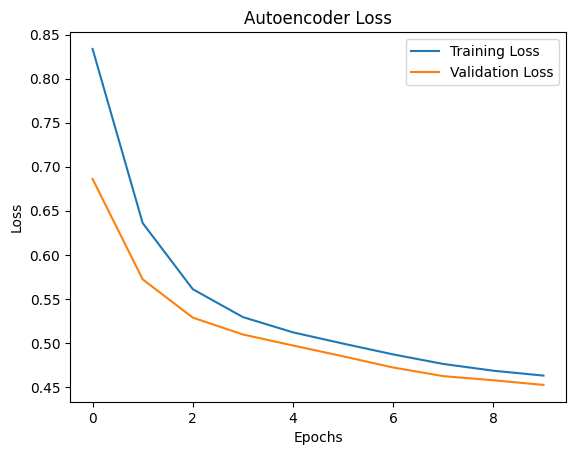

In [18]:
plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.title("Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()